In [2]:
import numpy as np # linear algebra
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from plotly.offline import init_notebook_mode, iplot
init_notebook_mode(connected=True)

## Setting up the Data

In [92]:
recipe = pd.read_json('./train.json')

In [4]:
recipe.head()

,id,cuisine,ingredients
0,10259,greek,"[romaine lettuce, black olives, grape tomatoes..."
1,25693,southern_us,"[plain flour, ground pepper, salt, tomatoes, g..."
2,20130,filipino,"[eggs, pepper, salt, mayonaise, cooking oil, g..."
3,22213,indian,"[water, vegetable oil, wheat, salt]"
4,13162,indian,"[black pepper, shallots, cornflour, cayenne pe..."


In [6]:
recipe['cuisine'].value_counts()

cuisine
italian         7838
mexican         6438
southern_us     4320
indian          3003
chinese         2673
french          2646
cajun_creole    1546
thai            1539
japanese        1423
greek           1175
spanish          989
korean           830
vietnamese       825
moroccan         821
british          804
filipino         755
irish            667
jamaican         526
russian          489
brazilian        467
Name: count, dtype: int64

In [8]:
all_ingredients = [] # list to store all ingredients
for indiv_ingredient_list in recipe['ingredients'].values:
    for ingredient in indiv_ingredient_list:
        all_ingredients.append(ingredient)

In [9]:
len(all_ingredients) # 4 lacs ingredients 

428275

In [26]:
# Convert that list in a Pandas DataFrame so that we can apply value_counts
ingredients_together = pd.DataFrame(all_ingredients)
ingredients_together

,0
0,romaine lettuce
1,black olives
2,grape tomatoes
3,garlic
4,pepper
...,...
428270,garlic
428271,white sugar
428272,roma tomatoes
428273,celery


In [12]:
ingredients_together.value_counts()[0:30] # for first 30

0                     
salt                      18049
olive oil                  7972
onions                     7972
water                      7457
garlic                     7380
sugar                      6434
garlic cloves              6237
butter                     4848
ground black pepper        4785
all-purpose flour          4632
pepper                     4438
vegetable oil              4385
eggs                       3388
soy sauce                  3296
kosher salt                3113
green onions               3078
tomatoes                   3058
large eggs                 2948
carrots                    2814
unsalted butter            2782
extra-virgin olive oil     2747
ground cumin               2747
black pepper               2627
milk                       2263
chili powder               2036
oil                        1970
red bell pepper            1939
purple onion               1896
scallions                  1891
grated parmesan cheese     1886
Name: count, dtyp

In [13]:
ingredients_together.value_counts()

0                          
salt                           18049
olive oil                       7972
onions                          7972
water                           7457
garlic                          7380
                               ...  
dark chocolate cocoa powder        1
dark crème de cacao                1
dark lager                         1
shishito chile                     1
padron peppers                     1
Name: count, Length: 6714, dtype: int64

## Let's work on prediction

In [15]:
recipe['cuisine'].value_counts()

cuisine
italian         7838
mexican         6438
southern_us     4320
indian          3003
chinese         2673
french          2646
cajun_creole    1546
thai            1539
japanese        1423
greek           1175
spanish          989
korean           830
vietnamese       825
moroccan         821
british          804
filipino         755
irish            667
jamaican         526
russian          489
brazilian        467
Name: count, dtype: int64

### Unique ingredient list assigned 1/0

In [28]:
unique_ingredients = ingredients_together.squeeze().value_counts().index.tolist()
ingredients_keys = {ingredient: i for i, ingredient in enumerate(unique_ingredients)}
ingredients_keys

{'salt': 0,
 'olive oil': 1,
 'onions': 2,
 'water': 3,
 'garlic': 4,
 'sugar': 5,
 'garlic cloves': 6,
 'butter': 7,
 'ground black pepper': 8,
 'all-purpose flour': 9,
 'pepper': 10,
 'vegetable oil': 11,
 'eggs': 12,
 'soy sauce': 13,
 'kosher salt': 14,
 'green onions': 15,
 'tomatoes': 16,
 'large eggs': 17,
 'carrots': 18,
 'unsalted butter': 19,
 'ground cumin': 20,
 'extra-virgin olive oil': 21,
 'black pepper': 22,
 'milk': 23,
 'chili powder': 24,
 'oil': 25,
 'red bell pepper': 26,
 'purple onion': 27,
 'scallions': 28,
 'grated parmesan cheese': 29,
 'sesame oil': 30,
 'corn starch': 31,
 'ginger': 32,
 'baking powder': 33,
 'jalapeno chilies': 34,
 'dried oregano': 35,
 'chopped cilantro fresh': 36,
 'fresh lemon juice': 37,
 'diced tomatoes': 38,
 'fresh parsley': 39,
 'minced garlic': 40,
 'chicken broth': 41,
 'sour cream': 42,
 'cayenne pepper': 43,
 'fresh ginger': 44,
 'brown sugar': 45,
 'cooking spray': 46,
 'shallots': 47,
 'garlic powder': 48,
 'lime': 49,
 'lemo

In [20]:
def ingredients_to_vector(chosen_ingredients):
    vector = np.zeros(len(ingredients_keys))
    for ingredient in chosen_ingredients:
        index = ingredients_keys.get(ingredient)
        if ingredient in unique_ingredients:
            vector[index] = 1
            # print(f"Ingredient: {ingredient}, Index: {index}, Vector: {vector[index]}")
    return vector

### Split input and output columns

In [37]:
X = np.array([ingredients_to_vector(ings) for ings in recipe['ingredients']])
Y = recipe['cuisine']
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 1., ..., 0., 0., 0.]])

In [38]:
Y

0              greek
1        southern_us
2           filipino
3             indian
4             indian
            ...     
39769          irish
39770        italian
39771          irish
39772        chinese
39773        mexican
Name: cuisine, Length: 39774, dtype: object

### Create test and train split

In [53]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=40,stratify=Y)

In [118]:
X_test

array([[0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       ...,
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

### Predict using SVC

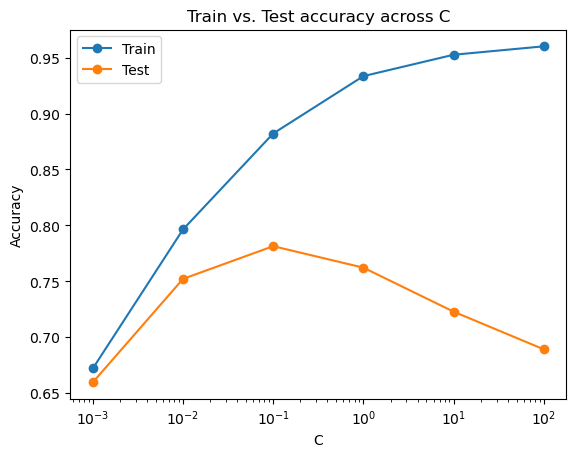

In [55]:
import matplotlib.pyplot as plt
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

test_Acc = []
train_Acc = []
C = [0.001, 0.01, 0.1, 1, 10, 100]
for c in C:
    model = LinearSVC(C=c, max_iter=5000)
    model.fit(X_train, Y_train)
    train_Acc.append(accuracy_score(Y_train, model.predict(X_train)))
    test_Acc.append(accuracy_score(Y_test, model.predict(X_test)))

plt.plot(C, train_Acc, marker="o", label="Train")
plt.plot(C, test_Acc, marker="o", label="Test")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Train vs. Test accuracy across C")
plt.show()

In [84]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import classification_report

final = CalibratedClassifierCV(LinearSVC(C=0.1, max_iter=5000), cv=5)
final.fit(X_train, Y_train)
pred = final.predict_proba(X_test)
cuisines = final.classes_

In [89]:
pred[0]

array([5.17761849e-04, 1.50264874e-02, 7.34096461e-02, 3.19779004e-03,
       1.27280643e-02, 6.02706269e-01, 1.49806864e-02, 4.78616506e-04,
       2.50263368e-03, 1.67260916e-01, 4.52263766e-04, 1.18882568e-02,
       4.61969976e-03, 3.62727444e-03, 7.84278048e-05, 9.70345793e-03,
       1.97012943e-02, 4.99775203e-02, 8.65256184e-04, 6.27767748e-03])

In [132]:
from numpy import argsort

for i in range(5):
    # random_index = np.random.randint(0, len(pred))
    top_cuisines = argsort(pred[i])[::-1][:3]
    actual_cuisine = Y_test.iloc[i]
    ingredient_names = np.array(unique_ingredients)
    present = np.array(ingredient_names[X_test[i] == 1])
    print(f"Actual Cuisine: {actual_cuisine}")
    for cuisine in top_cuisines:
        print(f"{cuisines[cuisine]}: {round(pred[i][cuisine] * 100, 3)}%")
    print(f"\nIngredients:", end=" ")
    for ing in present:
        print(f"{ing},", end=" ")
    print("\n")
    print("-------------------------------------------------------------------------------")
    print("\n")

Actual Cuisine: french
french: 60.271%
italian: 16.726%
cajun_creole: 7.341%

Ingredients: onions, garlic, ground black pepper, all-purpose flour, dry white wine, white sugar, bay leaf, vegetable broth, french bread, brandy, ground thyme, fat-free parmesan cheese, 

-------------------------------------------------------------------------------


Actual Cuisine: british
british: 56.667%
italian: 19.077%
southern_us: 7.824%

Ingredients: butter, all-purpose flour, baking powder, white sugar, ground ginger, confectioners sugar, golden syrup, 

-------------------------------------------------------------------------------


Actual Cuisine: mexican
mexican: 91.703%
thai: 2.06%
indian: 1.383%

Ingredients: onions, garlic, oil, purple onion, chicken broth, cilantro, lime juice, pork tenderloin, shredded cabbage, ancho powder, hominy, red enchilada sauce, roasted tomatoes, 

-------------------------------------------------------------------------------


Actual Cuisine: spanish
spanish: 39.

In [ ]:
top1 = 0
top3 = 0
pred = final.predict_proba(X_test)
for i in range(len(pred)):
    actual_cuisine = Y_test.iloc[i]
    top_cuisines = argsort(pred[i])[::-1][:3]
    # print(f"top: {top_cuisines}, actual: {actual_cuisine}")
    if actual_cuisine == cuisines[top_cuisines[0]]:
        top1 += 1
    if actual_cuisine == cuisines[top_cuisines[0]] or actual_cuisine == cuisines[top_cuisines[1]] or actual_cuisine == cuisines[top_cuisines[2]]:
        top3 += 1
print(f"Top-1 Accuracy: {top1 / len(pred) * 100:.2f}%")
print(f"Top-3 Accuracy: {top3 / len(pred) * 100:.2f}%")

Top-1 Accuracy: 78.15%
Top-3 Accuracy: 91.97%


In [127]:
ing_count = X.sum(axis=0)
min_in_cuisine = 15

for cuisine in cuisines:
    rows = X[Y == cuisine]
    in_cuisine_count = rows.sum(axis=0)
    
    precision = in_cuisine_count / ing_count
    precision[in_cuisine_count < min_in_cuisine] = 0
    
    top10 = np.argsort(precision)[::-1][:10]
    
    print(cuisine.upper())
    
    for j in top10:
        print(f" {unique_ingredients[j]}: {in_cuisine_count[j]} / {ing_count[j]} ({precision[j] * 100:.1f}%)")
    print("\n")
    print("------------------------------------------------")
    print("\n")

BRAZILIAN
 cachaca: 70.0 / 70.0 (100.0%)
 chocolate sprinkles: 16.0 / 18.0 (88.9%)
 dried black beans: 18.0 / 36.0 (50.0%)
 tapioca flour: 17.0 / 49.0 (34.7%)
 ice: 26.0 / 111.0 (23.4%)
 sweetened condensed milk: 57.0 / 271.0 (21.0%)
 ice cubes: 16.0 / 130.0 (12.3%)
 bananas: 21.0 / 224.0 (9.4%)
 coconut milk: 58.0 / 854.0 (6.8%)
 lime: 89.0 / 1439.0 (6.2%)


------------------------------------------------


BRITISH
 stilton cheese: 17.0 / 18.0 (94.4%)
 suet: 16.0 / 18.0 (88.9%)
 golden syrup: 21.0 / 30.0 (70.0%)
 double cream: 15.0 / 40.0 (37.5%)
 malt vinegar: 18.0 / 51.0 (35.3%)
 puff pastry: 16.0 / 51.0 (31.4%)
 dried currants: 26.0 / 95.0 (27.4%)
 frozen pastry puff sheets: 25.0 / 106.0 (23.6%)
 plain flour: 36.0 / 154.0 (23.4%)
 caster sugar: 26.0 / 130.0 (20.0%)


------------------------------------------------


CAJUN_CREOLE
 file powder: 46.0 / 49.0 (93.9%)
 andouille sausage: 224.0 / 267.0 (83.9%)
 creole seasoning: 216.0 / 276.0 (78.3%)
 cajun seasoning: 293.0 / 376.0 (77.